# Taller 07: clasificación de dígitos con KNN y RNN

**Integrantes:** Daniel Gómez, Jose Ballestas y Francesco Rosa

Se comparan K-Nearest Neighbors (KNN), que vota entre sus K vecinos más cercanos, y Radius Neighbors (RNN), que vota entre los ejemplos a distancia menor o igual al radio R. Se usa el conjunto digits de scikit-learn (imágenes de 8 × 8 píxeles, diez clases).

Se separan los datos en entrenamiento (80 %) y prueba (20 %). K y R se seleccionan solo mediante validación cruzada estratificada de 4 folds sobre entrenamiento. Las mismas particiones se usan en ambas búsquedas y la prueba se reserva para la evaluación final.

## 1. Librerías y datos

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

In [12]:
digits = load_digits()
X, y = digits.data, digits.target

print(f"Número de imágenes: {X.shape[0]}")
print(f"Características por imagen: {X.shape[1]} (64 píxeles)")
print(f"Clases: {np.unique(y)}")

Número de imágenes: 1797
Características por imagen: 64 (64 píxeles)
Clases: [0 1 2 3 4 5 6 7 8 9]


Cada imagen se representa con 64 intensidades de píxel. Aquí se muestran algunos ejemplos.

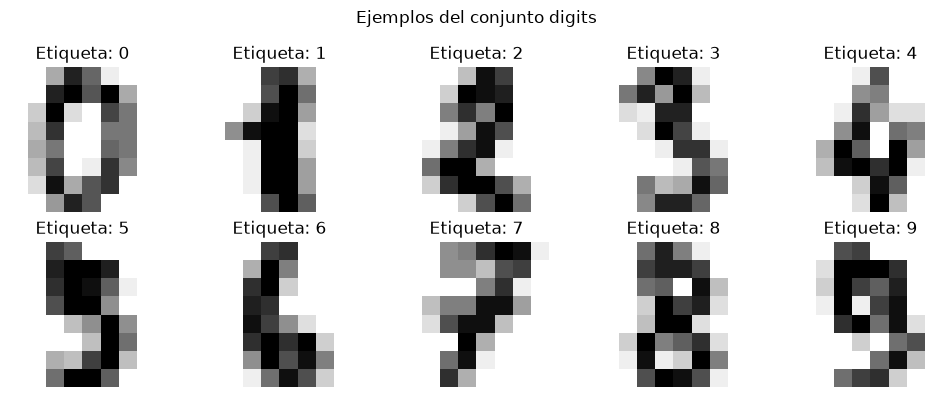

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.flat, digits.images[:10], y[:10]):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"Etiqueta: {label}")
    ax.axis("off")
plt.suptitle("Ejemplos del conjunto digits")
plt.tight_layout()
plt.show()

## 2. División entrenamiento/prueba y validación cruzada

La división estratificada conserva aproximadamente la proporción de cada dígito. Se separa antes de escalar. StandardScaler está dentro de un pipeline: en cada fold, se ajusta únicamente con la parte de entrenamiento de ese fold, evitando filtrar información de validación o prueba. Se preparan los folds una sola vez y se reutilizan en ambas búsquedas.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
folds = list(cv.split(X_train, y_train))

print(f"Entrenamiento: {len(X_train)} ejemplos ({len(X_train) / len(X):.0%})")
print(f"Prueba: {len(X_test)} ejemplos ({len(X_test) / len(X):.0%})")
print(f"Folds: {len(folds)}")

Entrenamiento: 1437 ejemplos (80%)
Prueba: 360 ejemplos (20%)
Folds: 4


## 3. Métricas

Se comparan accuracy (proporción total de aciertos), F1 macro (promedio del F1 de cada dígito, con el mismo peso por clase) y balanced accuracy (promedio del recall por clase). Se seleccionarán los parámetros por F1 macro promedio y se mostrarán las tres métricas en cada gráfica.

In [15]:
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
}

## 4. Búsqueda de K para KNN

Se exploran valores impares de K entre 1 y 31. El K impar reduce la posibilidad de empates en la votación. La distancia es euclidiana y las características se estandarizan dentro de cada fold.

In [16]:
k_values = list(range(1, 32, 2))
knn_rows = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k, metric="euclidean", algorithm="brute")
    )
    scores = cross_validate(
        model, X_train, y_train, cv=folds, scoring=scoring, n_jobs=-1
    )
    knn_rows.append({
        "K": k,
        **{metric: scores[f"test_{metric}"].mean() for metric in scoring},
    })

knn_results = pd.DataFrame(knn_rows)
knn_results.round(4)

,K,accuracy,f1_macro,balanced_accuracy
0,1,0.9687,0.9685,0.9685
1,3,0.9722,0.9721,0.9720
2,5,0.9756,0.9755,0.9756
3,7,0.9743,0.9741,0.9740
4,9,0.9680,0.9678,0.9677
5,11,0.9652,0.9650,0.9650
6,13,0.9555,0.9551,0.9552
7,15,0.9534,0.9530,0.9531
8,17,0.9499,0.9493,0.9496
9,19,0.9443,0.9438,0.9440


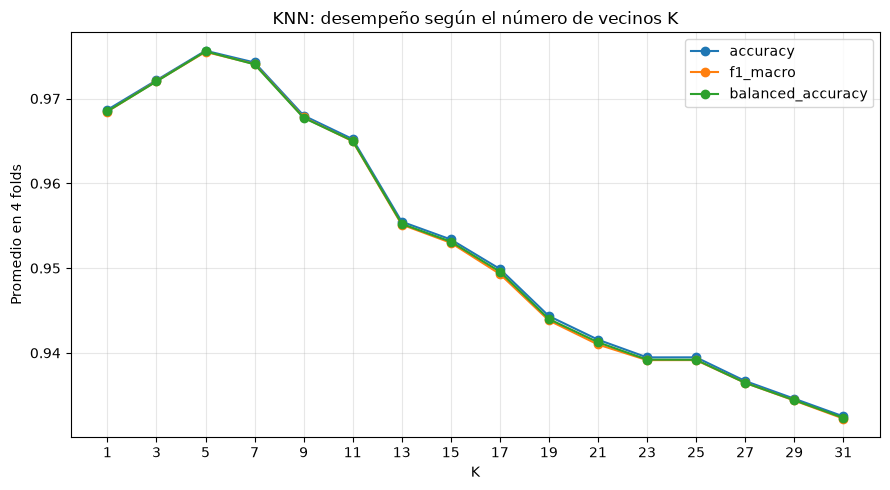

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
for metric in scoring:
    ax.plot(knn_results["K"], knn_results[metric], marker="o", label=metric)
ax.set(title="KNN: desempeño según el número de vecinos K",
       xlabel="K", ylabel="Promedio en 4 folds")
ax.set_xticks(k_values)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Seleccionamos explícitamente el K con mayor F1 macro promedio en validación cruzada. La selección no usa el conjunto de prueba.

In [18]:
best_k_row = knn_results.loc[knn_results["f1_macro"].idxmax()]
best_k = int(best_k_row["K"])
print(f"K seleccionado: {best_k}")
print(best_k_row[["accuracy", "f1_macro", "balanced_accuracy"]].round(4))

K seleccionado: 5
accuracy             0.9756
f1_macro             0.9755
balanced_accuracy    0.9756
Name: 2, dtype: float64


## 5. Búsqueda del radio R para Radius Neighbors

Radius Neighbors vota entre las observaciones a distancia euclidiana menor o igual a R. El escalado hace que la magnitud de R dependa de las características transformadas; se explora una malla de 4 a 16. Si el mejor valor queda en un extremo, se amplía el rango y se repite la búsqueda.

Si una consulta no tiene vecinos dentro del radio, se predice la clase más frecuente del fold de entrenamiento. Esto permite evaluar radios pequeños y las métricas reflejarán su efecto.

In [19]:
r_values = np.arange(4.0, 16.1, 1.0)
rnn_rows = []

for radius in r_values:
    model = make_pipeline(
        StandardScaler(),
        RadiusNeighborsClassifier(
            radius=radius, metric="euclidean", algorithm="brute",
            outlier_label="most_frequent"
        )
    )
    scores = cross_validate(
        model, X_train, y_train, cv=folds, scoring=scoring, n_jobs=-1
    )
    rnn_rows.append({
        "R": radius,
        **{metric: scores[f"test_{metric}"].mean() for metric in scoring},
    })

rnn_results = pd.DataFrame(rnn_rows)
rnn_results.round(4)

,R,accuracy,f1_macro,balanced_accuracy
0,4.0,0.6479,0.7023,0.6471
1,5.0,0.8810,0.8946,0.8805
2,6.0,0.9318,0.9353,0.9314
3,7.0,0.9095,0.9099,0.9090
4,8.0,0.8580,0.8567,0.8579
5,9.0,0.7064,0.7033,0.7070
6,10.0,0.4920,0.4831,0.4922
7,11.0,0.3306,0.2986,0.3301
8,12.0,0.2401,0.1960,0.2401
9,13.0,0.1761,0.1385,0.1758


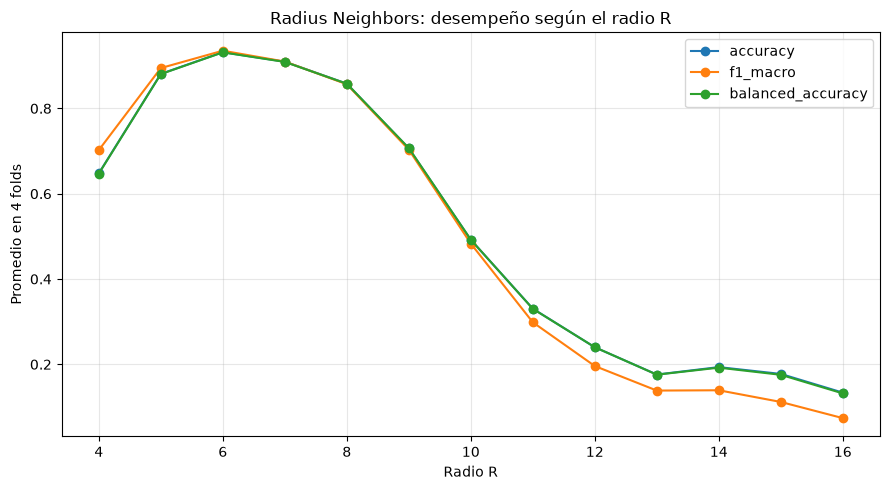

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
for metric in scoring:
    ax.plot(rnn_results["R"], rnn_results[metric], marker="o", label=metric)
ax.set(title="Radius Neighbors: desempeño según el radio R",
       xlabel="Radio R", ylabel="Promedio en 4 folds")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Seleccionamos R por el mayor F1 macro promedio. Si el máximo está en el borde, conviene ampliar el rango y repetir la validación cruzada.

In [21]:
best_r_row = rnn_results.loc[rnn_results["f1_macro"].idxmax()]
best_r = float(best_r_row["R"])
print(f"R seleccionado: {best_r:.1f}")
print(best_r_row[["accuracy", "f1_macro", "balanced_accuracy"]].round(4))
if best_r in (r_values[0], r_values[-1]):
    print("El máximo está en el borde: amplíe el rango de R y repita la búsqueda.")

R seleccionado: 6.0
accuracy             0.9318
f1_macro             0.9353
balanced_accuracy    0.9314
Name: 2, dtype: float64


## 6. Evaluación final en prueba

Con K y R seleccionados solo mediante validación cruzada, ajustamos cada pipeline con todo entrenamiento y evaluamos una vez en prueba. Se reportan las métricas y matrices de confusión.


KNN (K=5)

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.923     1.000     0.960        36
           2      0.946     1.000     0.972        35
           3      1.000     0.973     0.986        37
           4      0.971     0.944     0.958        36
           5      0.973     0.973     0.973        37
           6      0.973     1.000     0.986        36
           7      0.921     0.972     0.946        36
           8      0.969     0.886     0.925        35
           9      0.970     0.889     0.928        36

    accuracy                          0.964       360
   macro avg      0.965     0.964     0.963       360
weighted avg      0.965     0.964     0.964       360


Radius Neighbors (R=6.0)

              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.667     1.000     0.800        36
           2      1.000     1.000     1

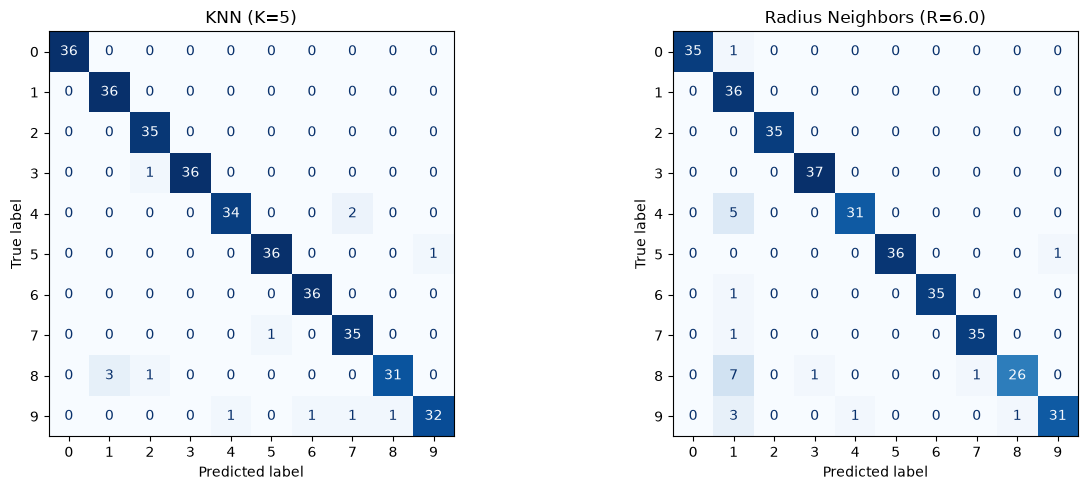

,Accuracy,F1 macro,Balanced accuracy
Modelo,,,
KNN (K=5),0.9639,0.9634,0.9637
Radius Neighbors (R=6.0),0.9361,0.9379,0.9355


In [22]:
final_models = {
    f"KNN (K={best_k})": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=best_k, metric="euclidean", algorithm="brute")
    ),
    f"Radius Neighbors (R={best_r:.1f})": make_pipeline(
        StandardScaler(),
        RadiusNeighborsClassifier(
            radius=best_r, metric="euclidean", algorithm="brute",
            outlier_label="most_frequent"
        )
    ),
}

test_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, final_models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_rows.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)
    print(f"\n{name}\n")
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))

plt.tight_layout()
plt.show()

test_results = pd.DataFrame(test_rows).set_index("Modelo")
test_results.round(4)

## 7. Conclusiones

La validación cruzada seleccionó **K = 5** para KNN (accuracy: **0.9756**, F1 macro: **0.9755**, balanced accuracy: **0.9756**) y **R = 6.0** para Radius Neighbors (accuracy: **0.9318**, F1 macro: **0.9353**, balanced accuracy: **0.9314**).

En la prueba, KNN obtuvo accuracy **0.9639**, F1 macro **0.9634** y balanced accuracy **0.9637**. Sus tres métricas fueron algo menores que los promedios de validación cruzada, con una diferencia cercana a 0.012. Radius Neighbors obtuvo **0.9361**, **0.9379** y **0.9355**, respectivamente; estos valores son ligeramente mayores que sus promedios de validación cruzada. En ambos conjuntos, KNN tuvo mejor desempeño global que Radius Neighbors, especialmente en F1 macro.

Según las matrices de confusión de prueba, KNN confundió más el **8 con el 1** (3 casos) y el **4 con el 7** (2 casos). Para Radius Neighbors, la confusión más frecuente fue **8 → 1** (7 casos), seguida de **4 → 1** (5 casos) y **9 → 1** (3 casos). El dígito 8 fue el más difícil para ambos modelos.

La prueba se mantuvo separada durante la selección de hiperparámetros y se usó una sola vez para esta evaluación final.